# Bank Marketing - will the client subscribe to a term deposit?
### Machine Learning - Assignment 2

Name: Sanjoy Mukherjee

BITS ID: 2026AJ05819

Dataset: Bank Marketing, UCI Machine Learning Repository (id 222), Moro et al., 2014.
https://archive.ics.uci.edu/dataset/222/bank+marketing

A Portuguese bank phoned its clients to sell a term deposit. Each row is one client and the
target `y` says whether the client subscribed (yes / no). In this notebook I train the five
classifiers, compare them on a test set and save the trained models for the Streamlit app.

## 1. Libraries

In [1]:
import os
import io
import json
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PowerTransformer, OneHotEncoder, Binarizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (make_scorer, accuracy_score, roc_auc_score,
                             precision_score, recall_score, f1_score,
                             matthews_corrcoef, ConfusionMatrixDisplay,
                             RocCurveDisplay)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 120)

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

scikit-learn 1.7.2 | pandas 2.2.3 | numpy 2.2.6


## 2. Getting the data

The UCI download contains two versions of the data. I use `bank-additional.csv`: 4,119
clients picked at random (10 %) from the newer full file, with 20 input columns. Compared
with the older version it adds five economic indicators for the time of the call. UCI says
the small file is meant for slower algorithms such as SVM, and that the economic columns
improve the predictions a lot when `duration` is not used (see step 4).

If the file is not already in `data/`, the cell below downloads it from UCI. The separator
is `;`.

In [2]:
DATA_FILE = "data/bank-additional.csv"
UCI_ZIP = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

if not os.path.exists(DATA_FILE):
    os.makedirs("data", exist_ok=True)
    with urllib.request.urlopen(UCI_ZIP) as response:
        outer_zip = zipfile.ZipFile(io.BytesIO(response.read()))
    inner_zip = zipfile.ZipFile(io.BytesIO(outer_zip.read("bank-additional.zip")))
    with open(DATA_FILE, "wb") as f:
        f.write(inner_zip.read("bank-additional/bank-additional.csv"))
    print("downloaded", DATA_FILE)

bank = pd.read_csv(DATA_FILE, sep=";")
print("shape:", bank.shape)
print("missing values:", bank.isna().sum().sum())
print("duplicate rows:", bank.duplicated().sum())
bank.head()

shape: (4119, 21)
missing values: 0
duplicate rows: 0


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,30,blue-collar,married,basic.9y,no,yes,no,cellular,may,fri,487,2,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
1,39,services,single,high.school,no,no,no,telephone,may,fri,346,4,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
2,25,services,married,high.school,no,yes,no,telephone,jun,wed,227,1,999,0,nonexistent,1.4,94.465,-41.8,4.962,5228.1,no
3,38,services,married,basic.9y,no,unknown,unknown,telephone,jun,fri,17,3,999,0,nonexistent,1.4,94.465,-41.8,4.959,5228.1,no
4,47,admin.,married,university.degree,no,yes,no,cellular,nov,mon,58,1,999,0,nonexistent,-0.1,93.200,-42.0,4.191,5195.8,no


## 3. Looking at the data

In [3]:
bank.describe().round(2)

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,4119.00,4119.00,4119.00,4119.00,4119.00,4119.00,4119.00,4119.00,4119.00,4119.00
mean,40.11,256.79,2.54,960.42,0.19,0.08,93.58,-40.50,3.62,5166.48
std,10.31,254.70,2.57,191.92,0.54,1.56,0.58,4.59,1.73,73.67
min,18.00,0.00,1.00,0.00,0.00,-3.40,92.20,-50.80,0.64,4963.60
25%,32.00,103.00,1.00,999.00,0.00,-1.80,93.08,-42.70,1.33,5099.10
50%,38.00,181.00,2.00,999.00,0.00,1.10,93.75,-41.80,4.86,5191.00
75%,47.00,317.00,3.00,999.00,0.00,1.40,93.99,-36.40,4.96,5228.10
max,88.00,3643.00,35.00,999.00,6.00,1.40,94.77,-26.90,5.04,5228.10


y
no     3668
yes     451
Name: count, dtype: int64
share of yes: 0.109


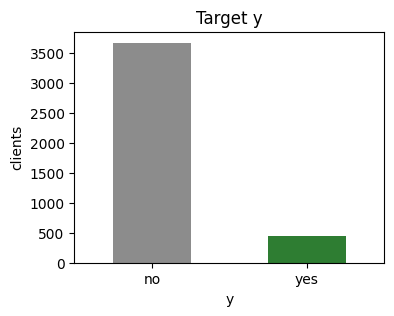

In [4]:
counts = bank["y"].value_counts()
print(counts)
print("share of yes: %.3f" % (counts["yes"] / len(bank)))

counts.plot(kind="bar", color=["#8c8c8c", "#2e7d32"], figsize=(4, 3), rot=0)
plt.title("Target y")
plt.ylabel("clients")
plt.show()

Only 451 of the 4,119 clients (about 11 %) said yes. A model that always answers "no" would
already get about 89 % accuracy, so accuracy alone says little here. I look mainly at F1
and MCC, and I use MCC to tune the models.

There are no empty cells, but six columns use the word "unknown" for a missing answer
(UCI mentions this). I keep "unknown" as a category of its own:

In [5]:
text_cols = bank.select_dtypes(exclude="number").columns.drop("y")
unknowns = (bank[text_cols] == "unknown").sum()
unknowns[unknowns > 0]

job           39
marital       11
education    167
default      803
housing      105
loan         105
dtype: int64

Share of "yes" for a few columns:

In [6]:
said_yes = bank["y"].eq("yes")
for col in ["poutcome", "contact", "month"]:
    summary = said_yes.groupby(bank[col]).agg(["mean", "size"])
    summary.columns = ["share of yes", "clients"]
    print(summary.round(3).sort_values("share of yes", ascending=False))
    print()

             share of yes  clients
poutcome                          
success             0.648      142
failure             0.148      454
nonexistent         0.083     3523

           share of yes  clients
contact                         
cellular          0.141     2652
telephone         0.052     1467

       share of yes  clients
month                       
mar           0.583       48
dec           0.545       22
sep           0.406       64
oct           0.362       69
apr           0.167      215
jun           0.128      530
aug           0.101      636
nov           0.096      446
jul           0.083      711
may           0.065     1378



Clients whose previous campaign ended in success subscribed far more often (about 65 %) than
the rest, and clients called on a mobile (cellular) did better than on a landline. The month
matters too: May has by far the most calls (1,378) but the lowest rate (6.5 %).

## 4. Removing `duration`

`duration` is the length of the last call in seconds. The UCI notes for this dataset say it
strongly affects the target but is only known after the call is over, and by then the answer
is known as well. It should be left out if the model is meant for real use, so I drop it. The
medians show how much it would leak:

In [7]:
print(bank.groupby("y")["duration"].median())
bank = bank.drop(columns="duration")
print("input columns left:", bank.shape[1] - 1)

y
no     165.0
yes    458.0
Name: duration, dtype: float64
input columns left: 19


## 5. Preprocessing

The 19 input columns are handled in five groups:

- `age`: standard scaling.
- `campaign`, `previous`: counts with a long right tail, so a Yeo-Johnson power transform
  (it also standardises the result).
- the five economic indicators: standard scaling. They are measured for the time of the call,
  not for the client, and several of them move together (see the correlations below).
- `pdays`: days since the client was last contacted, where 999 means never contacted. Almost
  every row is 999, so I turn it into one 0/1 column (1 = never contacted) with a `Binarizer`.
- the ten text columns: one-hot encoded, "unknown" included. A value that never appeared in
  training is ignored.

In [8]:
age_col = ["age"]
count_cols = ["campaign", "previous"]
econ_cols = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
pdays_col = ["pdays"]
cat_cols = ["job", "marital", "education", "default", "housing", "loan",
            "contact", "month", "day_of_week", "poutcome"]
feature_cols = age_col + count_cols + econ_cols + pdays_col + cat_cols
print(len(feature_cols), "input features")

print()
print("skewness of campaign and previous:")
print(bank[count_cols].skew().round(2))
print()
print("pdays = 999 in", (bank["pdays"] == 999).sum(), "of", len(bank), "rows")
print()
bank[econ_cols].corr().round(2)

19 input features

skewness of campaign and previous:
campaign    4.00
previous    4.02
dtype: float64

pdays = 999 in 3959 of 4119 rows



,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
emp.var.rate,1.00,0.76,0.20,0.97,0.90
cons.price.idx,0.76,1.00,0.05,0.66,0.47
cons.conf.idx,0.20,0.05,1.00,0.28,0.11
euribor3m,0.97,0.66,0.28,1.00,0.94
nr.employed,0.90,0.47,0.11,0.94,1.00


In [9]:
prep = ColumnTransformer([
    ("age", StandardScaler(), age_col),
    ("counts", PowerTransformer(method="yeo-johnson"), count_cols),
    ("econ", StandardScaler(), econ_cols),
    ("never_contacted", Binarizer(threshold=998), pdays_col),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])

## 6. Train / test split

80 % for training and 20 % for testing, stratified so both parts keep the same share of
"yes". The test part is saved as `test_data.csv` with the 19 input columns and `y`, in the
same form as the original file. This is the file to upload in the Streamlit app.

In [10]:
X = bank[feature_cols]
y = (bank["y"] == "yes").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("train:", X_train.shape, " share of yes %.3f" % y_train.mean())
print("test :", X_test.shape, " share of yes %.3f" % y_test.mean())

bank.loc[X_test.index].to_csv("test_data.csv", index=False)
print("saved test_data.csv with", len(X_test), "rows")

train: (3295, 19)  share of yes 0.110
test : (824, 19)  share of yes 0.109
saved test_data.csv with 824 rows


## 7. Training the five models

Each model is a pipeline: the preprocessing from step 5 followed by the classifier, so a saved
model takes the raw columns directly. A few settings of each model are searched with a grid search and 5-fold stratified
cross-validation that only sees the training rows. MCC is used to pick the best settings, because it
uses all four cells of the confusion matrix and is not fooled by the large "no" class.

In [11]:
mcc_scorer = make_scorer(matthews_corrcoef)
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

search_space = {
    "Logistic Regression": (
        LogisticRegression(max_iter=5000),
        {"C": [0.01, 0.1, 1, 10, 100], "class_weight": [None, "balanced"]}),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"criterion": ["gini", "entropy"], "max_depth": [3, 4, 5, 6, 8, 10],
         "min_samples_leaf": [1, 10, 25, 50], "class_weight": [None, "balanced"]}),
    "KNN": (
        KNeighborsClassifier(),
        {"n_neighbors": [3, 5, 7, 9, 11, 15, 21], "weights": ["uniform", "distance"],
         "p": [1, 2]}),
    "Naive Bayes": (
        GaussianNB(),
        {"var_smoothing": [1e-9, 1e-7, 1e-5, 1e-3, 1e-2, 1e-1, 1.0]}),
    "Support Vector Machine": (
        SVC(kernel="rbf", random_state=RANDOM_STATE),
        {"C": [0.1, 1, 10], "gamma": ["scale", 0.01, 0.1],
         "class_weight": [None, "balanced"]}),
}

tuned = {}
cv_summary = []
for name, (clf, params) in search_space.items():
    pipe = Pipeline([("prep", prep), ("model", clf)])
    gs = GridSearchCV(pipe, {"model__" + k: v for k, v in params.items()},
                      scoring=mcc_scorer, cv=folds, n_jobs=-1)
    gs.fit(X_train, y_train)
    tuned[name] = gs.best_estimator_
    cv_summary.append({
        "Model": name,
        "CV MCC": round(gs.best_score_, 4),
        "Best settings": {k.replace("model__", ""): v for k, v in gs.best_params_.items()},
    })

pd.DataFrame(cv_summary).set_index("Model")

,CV MCC,Best settings
Model,,
Logistic Regression,0.3548,"{'C': 0.1, 'class_weight': 'balanced'}"
Decision Tree,0.3979,"{'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 10}"
KNN,0.3103,"{'n_neighbors': 7, 'p': 1, 'weights': 'distance'}"
Naive Bayes,0.3453,{'var_smoothing': 1.0}
Support Vector Machine,0.3849,"{'C': 10, 'class_weight': 'balanced', 'gamma': 0.01}"


## 8. Results on the test set

For every model the predicted class comes from `predict()`. AUC needs a score for "yes": the
first four models give a probability with `predict_proba()`. The SVM does not give
probabilities here, so its AUC uses `decision_function()` (signed distance from the boundary).
AUC only depends on how the clients are ranked, so this score works just as well. "yes" is
the positive class for precision, recall, F1 and MCC.

In [12]:
def yes_score(model, X_part):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X_part)[:, 1]
    return model.decision_function(X_part)


def get_scores(model, X_part, y_part):
    y_pred = model.predict(X_part)
    return {
        "Accuracy": accuracy_score(y_part, y_pred),
        "AUC": roc_auc_score(y_part, yes_score(model, X_part)),
        "Precision": precision_score(y_part, y_pred, zero_division=0),
        "Recall": recall_score(y_part, y_pred),
        "F1": f1_score(y_part, y_pred),
        "MCC": matthews_corrcoef(y_part, y_pred),
    }

comparison = pd.DataFrame({name: get_scores(m, X_test, y_test)
                           for name, m in tuned.items()}).T.round(4)
comparison.index.name = "ML Model Name"
comparison

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.8337,0.7776,0.3464,0.5889,0.4362,0.3631
Decision Tree,0.8556,0.7520,0.3821,0.5222,0.4413,0.3665
KNN,0.8774,0.6872,0.3333,0.1222,0.1789,0.1468
Naive Bayes,0.8908,0.7598,0.5000,0.2667,0.3478,0.3116
Support Vector Machine,0.8580,0.7415,0.3969,0.5778,0.4706,0.4011


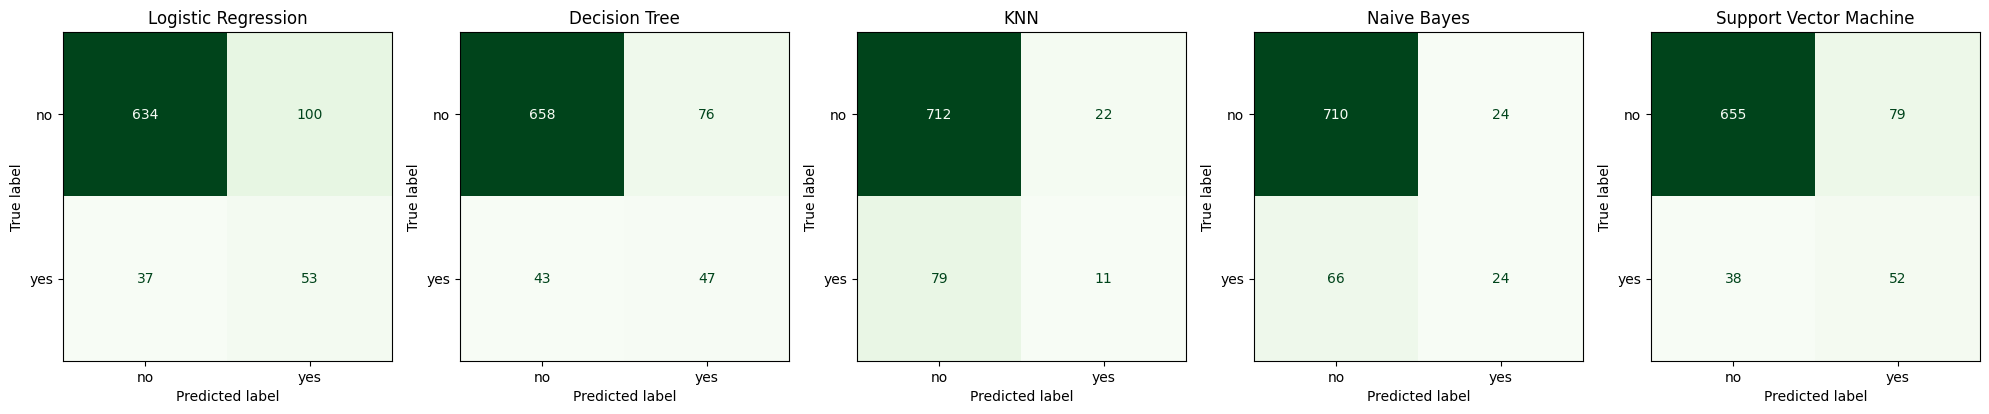

In [13]:
fig, axs = plt.subplots(1, 5, figsize=(20, 4))
for ax, (name, m) in zip(axs, tuned.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, m.predict(X_test), display_labels=["no", "yes"],
        cmap="Greens", colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

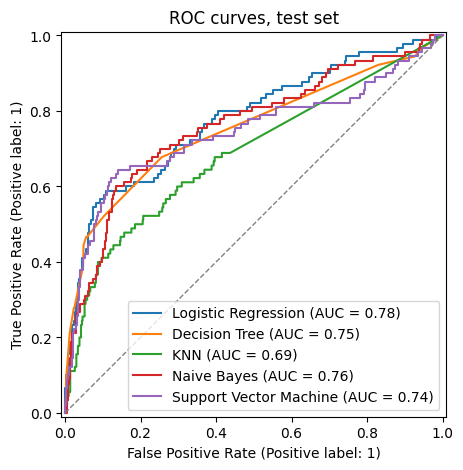

In [14]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, m in tuned.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", linewidth=1)
ax.set_title("ROC curves, test set")
plt.show()

A few details used in the observations below: which inputs the tree and the logistic regression rely on most, the number of columns after preprocessing, and the size of the SVM.

In [15]:
tree_pipe = tuned["Decision Tree"]
names_out = tree_pipe.named_steps["prep"].get_feature_names_out()
importance = pd.Series(tree_pipe.named_steps["model"].feature_importances_, index=names_out)
print("Decision Tree, top 5 importances:")
print(importance.sort_values(ascending=False).head(5).round(3))

lr_pipe = tuned["Logistic Regression"]
coefs = pd.Series(lr_pipe.named_steps["model"].coef_[0],
                  index=lr_pipe.named_steps["prep"].get_feature_names_out())
print()
print("Logistic Regression, largest coefficients (by size):")
print(coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(5).round(3))

print()
print("columns after preprocessing:", len(names_out))
svm_model = tuned["Support Vector Machine"].named_steps["model"]
print("SVM support vectors:", svm_model.n_support_.sum(), "of", len(X_train), "training rows")

Decision Tree, top 5 importances:
econ__nr.employed         0.678
econ__euribor3m           0.095
cat__poutcome_success     0.033
cat__contact_telephone    0.033
cat__job_self-employed    0.029
dtype: float64

Logistic Regression, largest coefficients (by size):
cat__month_mar            0.726
never_contacted__pdays   -0.594
econ__emp.var.rate       -0.572
cat__month_may           -0.415
cat__month_nov           -0.407
dtype: float64

columns after preprocessing: 62
SVM support vectors: 1904 of 3295 training rows


## 9. Saving the models

Each `.pkl` file in `model/` is a full pipeline (preprocessing + classifier), so the app only
has to load it and predict on the uploaded test file. The fitted preprocessing is also saved on
its own, together with the column list and the results table.

In [16]:
os.makedirs("model", exist_ok=True)
file_of = {
    "Logistic Regression": "lr_pipeline.pkl",
    "Decision Tree": "dt_pipeline.pkl",
    "KNN": "knn_pipeline.pkl",
    "Naive Bayes": "nb_pipeline.pkl",
    "Support Vector Machine": "svm_pipeline.pkl",
}
for name, m in tuned.items():
    joblib.dump(m, os.path.join("model", file_of[name]))

joblib.dump(tuned["Logistic Regression"].named_steps["prep"], "model/preprocessing.pkl")
comparison.to_csv("model/comparison.csv")

with open("model/columns.json", "w") as f:
    json.dump({"features": feature_cols, "target": "y", "positive_class": "yes",
               "dropped": ["duration"], "model_files": file_of}, f, indent=2)

for fname in sorted(os.listdir("model")):
    print(fname)

columns.json
comparison.csv
dt_pipeline.pkl
knn_pipeline.pkl
lr_pipeline.pkl
nb_pipeline.pkl
preprocessing.pkl
svm_pipeline.pkl


## 10. Observations

| ML Model Name | Observation about model performance |
|---|---|
| Logistic Regression | Highest AUC (0.778), so it is the best at ranking clients from most to least likely to subscribe. With balanced class weights it finds 53 of the 90 subscribers in the test set (recall 0.589), but precision is only 0.346: about two out of three clients it flags do not subscribe. Cross-validation chose fairly strong regularisation (C = 0.1). Its MCC (0.363) is third of the five. |
| Decision Tree | Best cross-validation MCC (about 0.40), but on the test set it comes second on F1 (0.441) and MCC (0.367), behind the SVM. It finds 47 of the 90 subscribers with precision 0.382. The tree (depth 5, at least 10 clients per leaf) relies mostly on `nr.employed`, which has about 68 % of the importance, so it mainly splits on the economic situation at the time of the call. |
| KNN | Weakest model: lowest AUC (0.690), F1 (0.179) and MCC (0.147). It finds only 11 of the 90 subscribers. Its accuracy of 0.877 is even below the 0.891 that a model gets by always saying "no". KNN has no class weights, so most neighbours of any client are "no" clients, and 53 of the 62 columns after preprocessing are one-hot 0/1 columns, which makes the distances less meaningful. |
| Naive Bayes | Highest accuracy (0.891) and precision (0.500), but that accuracy is exactly the "always no" level, and it finds only 24 of the 90 subscribers (recall 0.267). Its independence assumption does not hold here: `emp.var.rate`, `euribor3m` and `nr.employed` are correlated at 0.90 to 0.97, so the same information is counted more than once, and the one-hot columns are not Gaussian. Cross-validation picked the largest smoothing value in the grid (1.0), which suggests the normal curves fit these columns badly. |
| Support Vector Machine | Best F1 (0.471) and best MCC (0.401). It finds 52 of the 90 subscribers, almost as many as Logistic Regression, with 79 false alarms instead of 100. Its AUC (0.741) is lower than that of Logistic Regression, so its ranking is a little worse, but at its own decision boundary it gives the best balance. It is also the heaviest model to run: it keeps about 1,900 of the 3,295 training clients (more than half) as support vectors. |
| **Overall, winner for your dataset?** | **Support Vector Machine**. It scores highest on both F1 and MCC, and these are the fairer measures here because only about 11 % of the clients are positive. Logistic Regression is a close second and has the best AUC, so it would be the better choice if the bank wants a ranked list of clients to call first. All five models are only moderate (MCC at most 0.40). This is expected once `duration` is removed, because the model has to decide before the call is made. |